In [ ]:
!pip install pandas

In [ ]:
!pip install -q kagglehub pandas matplotlib seaborn scikit-learn

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import kagglehub
sns.set_theme(style="whitegrid")

In [ ]:
path = kagglehub.dataset_download("usdot/flight-delays")
print(path)

import os
print(os.listdir(path))

100%|██████████| 191M/191M [00:01<00:00, 115MB/s]

Extracting files...


/root/.cache/kagglehub/datasets/usdot/flight-delays/versions/1
['flights.csv', 'airports.csv', 'airlines.csv']


In [ ]:
flights = pd.read_csv(f"{path}/flights.csv",nrows=500_000, low_memory=False)
airlines = pd.read_csv(f"{path}/airlines.csv")
airports = pd.read_csv(f"{path}/airports.csv")

print(flights.shape)
flights.head()

(500000, 31)


,YEAR,MONTH,DAY,DAY_OF_WEEK,AIRLINE,FLIGHT_NUMBER,TAIL_NUMBER,ORIGIN_AIRPORT,DESTINATION_AIRPORT,SCHEDULED_DEPARTURE,...,ARRIVAL_TIME,ARRIVAL_DELAY,DIVERTED,CANCELLED,CANCELLATION_REASON,AIR_SYSTEM_DELAY,SECURITY_DELAY,AIRLINE_DELAY,LATE_AIRCRAFT_DELAY,WEATHER_DELAY
0,2015,1,1,4,AS,98,N407AS,ANC,SEA,5,...,408.0,-22.0,0,0,NaN,NaN,NaN,NaN,NaN,NaN
1,2015,1,1,4,AA,2336,N3KUAA,LAX,PBI,10,...,741.0,-9.0,0,0,NaN,NaN,NaN,NaN,NaN,NaN
2,2015,1,1,4,US,840,N171US,SFO,CLT,20,...,811.0,5.0,0,0,NaN,NaN,NaN,NaN,NaN,NaN
3,2015,1,1,4,AA,258,N3HYAA,LAX,MIA,20,...,756.0,-9.0,0,0,NaN,NaN,NaN,NaN,NaN,NaN
4,2015,1,1,4,AS,135,N527AS,SEA,ANC,25,...,259.0,-21.0,0,0,NaN,NaN,NaN,NaN,NaN,NaN


In [ ]:
flights = pd.read_csv(
    f"{path}/flights.csv",
    skiprows=lambda i: i > 0 and np.random.rand() > 0.1,
    low_memory=False
)

In [ ]:
flights.info()
flights.isna().sum().sort_values(ascending=False).head(15)
flights[["DEPARTURE_DELAY", "ARRIVAL_DELAY"]].describe()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 581727 entries, 0 to 581726
Data columns (total 31 columns):
 #   Column               Non-Null Count   Dtype  
---  ------               --------------   -----  
 0   YEAR                 581727 non-null  int64  
 1   MONTH                581727 non-null  int64  
 2   DAY                  581727 non-null  int64  
 3   DAY_OF_WEEK          581727 non-null  int64  
 4   AIRLINE              581727 non-null  object 
 5   FLIGHT_NUMBER        581727 non-null  int64  
 6   TAIL_NUMBER          580241 non-null  object 
 7   ORIGIN_AIRPORT       581727 non-null  object 
 8   DESTINATION_AIRPORT  581727 non-null  object 
 9   SCHEDULED_DEPARTURE  581727 non-null  int64  
 10  DEPARTURE_TIME       573147 non-null  float64
 11  DEPARTURE_DELAY      573147 non-null  float64
 12  TAXI_OUT             572882 non-null  float64
 13  WHEELS_OFF           572882 non-null  float64
 14  SCHEDULED_TIME       581727 non-null  int64  
 15  ELAPSED_TIME     

,DEPARTURE_DELAY,ARRIVAL_DELAY
count,573147.000000,571295.000000
mean,9.407178,4.446843
std,37.379695,39.557065
min,-42.000000,-76.000000
25%,-5.000000,-13.000000
50%,-2.000000,-5.000000
75%,7.000000,8.000000
max,1557.000000,1554.000000


In [ ]:
cancelled = flights[flights["CANCELLED"]== 1]
df = flights[(flights["CANCELLED"]== 0) & (flights["DIVERTED"] == 0)].copy()

df["IS_DELAYED"] = (df["ARRIVAL_DELAY"] > 15).astype(int)

df = df.merge(airlines, left_on="AIRLINE", right_on="IATA_CODE", how="left",
              suffixes=("", "_NAME"))
df = df.rename(columns={"AIRLINE_NAME": "AIRLINE_FULL"})

print(f"Delay rate: {df['IS_DELAYED'].mean():.1%}")


Delay rate: 17.9%


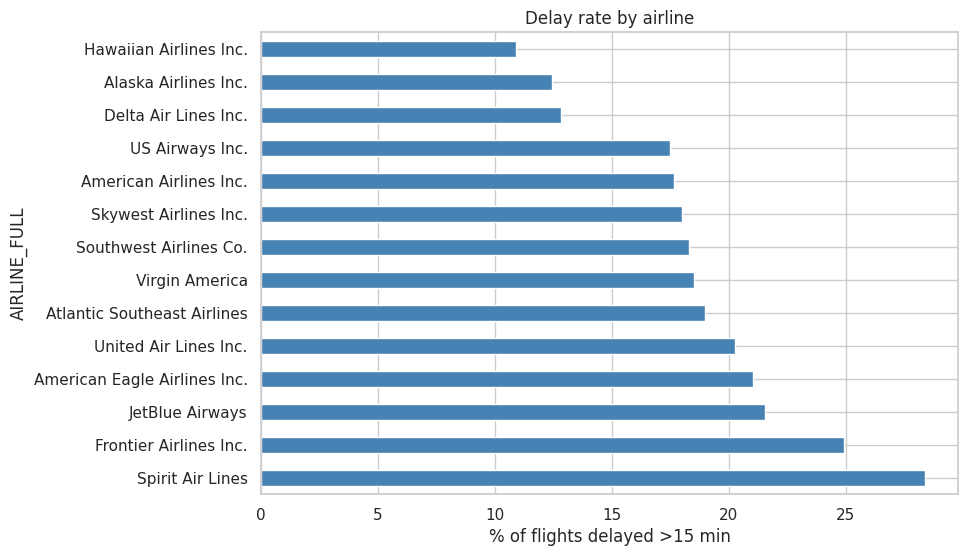

In [ ]:
delay_by_airline = (df.groupby("AIRLINE_FULL")["IS_DELAYED"]
                      .mean().sort_values(ascending=False) * 100)

delay_by_airline.plot(kind="barh", figsize=(9, 6), color="steelblue")
plt.xlabel("% of flights delayed >15 min")
plt.title("Delay rate by airline")
plt.show()

In [ ]:

df["DEP_HOUR"] = (df["SCHEDULED_DEPARTURE"] // 100).clip(upper=23)

day_names = {1: "Mon", 2: "Tue", 3: "Wed", 4: "Thu", 5: "Fri", 6: "Sat", 7: "Sun"}
df["DAY_NAME"] = df["DAY_OF_WEEK"].map(day_names)

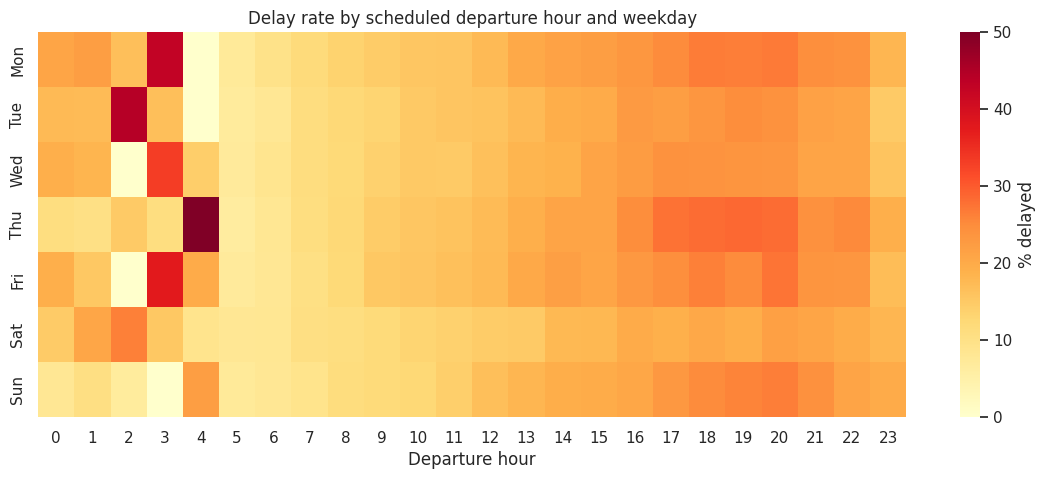

In [ ]:
pivot = (df.pivot_table(index="DAY_NAME", columns="DEP_HOUR",
                        values="IS_DELAYED", aggfunc="mean") * 100)
pivot = pivot.reindex(["Mon", "Tue", "Wed", "Thu", "Fri", "Sat", "Sun"])

plt.figure(figsize=(14, 5))
sns.heatmap(pivot, cmap="YlOrRd", annot=False, cbar_kws={"label": "% delayed"})
plt.title("Delay rate by scheduled departure hour and weekday")
plt.xlabel("Departure hour")
plt.ylabel("")
plt.show()

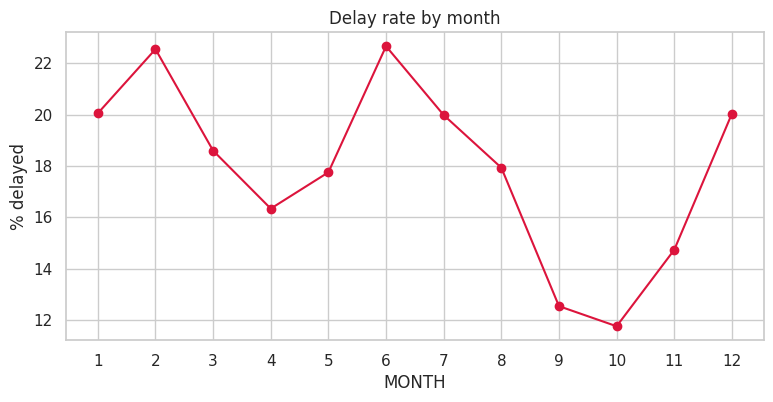

In [ ]:
monthly = df.groupby("MONTH")["IS_DELAYED"].mean() * 100

monthly.plot(marker="o", figsize=(9, 4), color="crimson")
plt.xticks(range(1, 13))
plt.ylabel("% delayed")
plt.title("Delay rate by month")
plt.show()

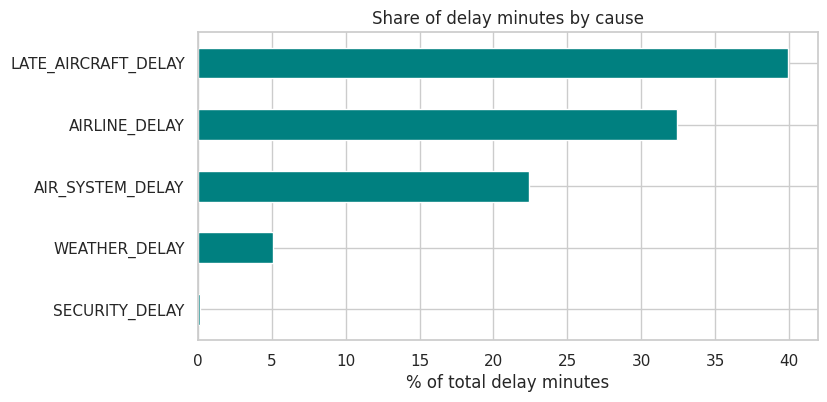

In [ ]:
cause_cols = ["AIR_SYSTEM_DELAY", "SECURITY_DELAY", "AIRLINE_DELAY",
              "LATE_AIRCRAFT_DELAY", "WEATHER_DELAY"]

causes = df.loc[df["IS_DELAYED"] == 1, cause_cols].fillna(0).sum()
causes = (causes / causes.sum() * 100).sort_values()

causes.plot(kind="barh", figsize=(8, 4), color="teal")
plt.xlabel("% of total delay minutes")
plt.title("Share of delay minutes by cause")
plt.show()

In [ ]:
airport_stats = (df.groupby("ORIGIN_AIRPORT")
                   .agg(flights=("IS_DELAYED", "size"),
                        delay_rate=("IS_DELAYED", "mean"),
                        avg_dep_delay=("DEPARTURE_DELAY", "mean"))
                   .query("flights >= 1000")
                   .sort_values("delay_rate", ascending=False))

airport_stats = airport_stats.merge(airports[["IATA_CODE", "AIRPORT", "CITY", "STATE"]],
                                    left_index=True, right_on="IATA_CODE", how="left")
airport_stats.head(10)

,flights,delay_rate,avg_dep_delay,IATA_CODE,AIRPORT,CITY,STATE
182.0,9368,0.236550,13.627775,LGA,LaGuardia Airport (Marine Air Terminal),New York,NY
228.0,27506,0.232640,14.094997,ORD,Chicago O'Hare International Airport,Chicago,IL
203.0,6668,0.231554,13.440762,MIA,Miami International Airport,Miami,FL
51.0,8463,0.221316,13.561385,BWI,Baltimore-Washington International Airport,Baltimore,MD
185.0,1021,0.220372,15.068560,LIT,Bill and Hillary Clinton National Airport (Ada...,Little Rock,AR
166.0,9174,0.219642,11.877807,JFK,John F. Kennedy International Airport (New Yor...,New York,NY
235.0,2312,0.218858,13.325260,PBI,Palm Beach International Airport,West Palm Beach,FL
195.0,7934,0.215906,13.376481,MDW,Chicago Midway International Airport,Chicago,IL
86.0,23355,0.214344,11.983687,DFW,Dallas/Fort Worth International Airport,Dallas-Fort Worth,TX
238.0,6346,0.213835,10.376930,PHL,Philadelphia International Airport,Philadelphia,PA


In [ ]:
df["ROUTE"] = df["ORIGIN_AIRPORT"].astype(str) + " → " + df["DESTINATION_AIRPORT"].astype(str)

routes = (df.groupby("ROUTE")
            .agg(flights=("IS_DELAYED", "size"),
                 delay_rate=("IS_DELAYED", "mean"))
            .query("flights >= 300")
            .sort_values("delay_rate", ascending=False)
            .head(10))

routes["delay_rate"] = (routes["delay_rate"] * 100).round(1)
routes

,flights,delay_rate
ROUTE,,
ORD → MSP,645,31.6
ORD → LAS,424,30.9
ORD → DEN,554,30.9
ORD → EWR,377,30.2
SJC → LAX,618,29.9
OAK → LAX,648,29.6
IAH → LAX,463,28.7
CLT → LGA,353,28.6
LGA → DTW,382,28.3


In [ ]:
model_df = df.copy()

model_df["ORIGIN_AIRPORT"] = model_df["ORIGIN_AIRPORT"].astype(str)
model_df["DESTINATION_AIRPORT"] = model_df["DESTINATION_AIRPORT"].astype(str)

for col in ["ORIGIN_AIRPORT", "DESTINATION_AIRPORT"]:
    top = model_df[col].value_counts().nlargest(100).index
    model_df[col] = model_df[col].where(model_df[col].isin(top), "OTHER")

model_df["IS_WEEKEND"] = model_df["DAY_OF_WEEK"].isin([6, 7]).astype(int)
model_df["IS_EVENING"] = (model_df["DEP_HOUR"] >= 17).astype(int)

num_features = ["MONTH", "DAY_OF_WEEK", "DEP_HOUR", "DISTANCE",
                "SCHEDULED_TIME", "IS_WEEKEND", "IS_EVENING"]
cat_features = ["AIRLINE", "ORIGIN_AIRPORT", "DESTINATION_AIRPORT"]

model_df = model_df.dropna(subset=num_features + cat_features + ["IS_DELAYED"])

X = model_df[num_features + cat_features]
y = model_df["IS_DELAYED"]
print(X.shape, f"Delay rate: {y.mean():.1%}")

(571295, 10) Delay rate: 17.9%


In [ ]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

In [ ]:
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import classification_report, roc_auc_score

preprocess = ColumnTransformer([
    ("num", StandardScaler(), num_features),
    ("cat", OneHotEncoder(handle_unknown="ignore"), cat_features),
])

logreg = Pipeline([
    ("prep", preprocess),
    ("clf", LogisticRegression(max_iter=1000, class_weight="balanced")),
])

logreg.fit(X_train, y_train)

lr_proba = logreg.predict_proba(X_test)[:, 1]
print("Logistic Regression ROC-AUC:", round(roc_auc_score(y_test, lr_proba), 3))
print(classification_report(y_test, logreg.predict(X_test)))

Logistic Regression ROC-AUC: 0.639
              precision    recall  f1-score   support

           0       0.88      0.59      0.70     93822
           1       0.25      0.62      0.35     20437

    accuracy                           0.59    114259
   macro avg       0.56      0.60      0.53    114259
weighted avg       0.76      0.59      0.64    114259



In [ ]:
from sklearn.ensemble import HistGradientBoostingClassifier
from sklearn.preprocessing import OrdinalEncoder

gb_prep = ColumnTransformer([
    ("num", "passthrough", num_features),
    ("cat", OrdinalEncoder(handle_unknown="use_encoded_value", unknown_value=-1),
     cat_features),
])

gb = Pipeline([
    ("prep", gb_prep),
    ("clf", HistGradientBoostingClassifier(
        categorical_features=[len(num_features) + i for i in range(len(cat_features))],
        max_iter=200, learning_rate=0.1, class_weight="balanced", random_state=42)),
])

gb.fit(X_train, y_train)

gb_proba = gb.predict_proba(X_test)[:, 1]
print("Gradient Boosting ROC-AUC:", round(roc_auc_score(y_test, gb_proba), 3))
print(classification_report(y_test, gb.predict(X_test)))

Gradient Boosting ROC-AUC: 0.682
              precision    recall  f1-score   support

           0       0.89      0.64      0.74     93822
           1       0.27      0.63      0.38     20437

    accuracy                           0.63    114259
   macro avg       0.58      0.63      0.56    114259
weighted avg       0.78      0.63      0.68    114259



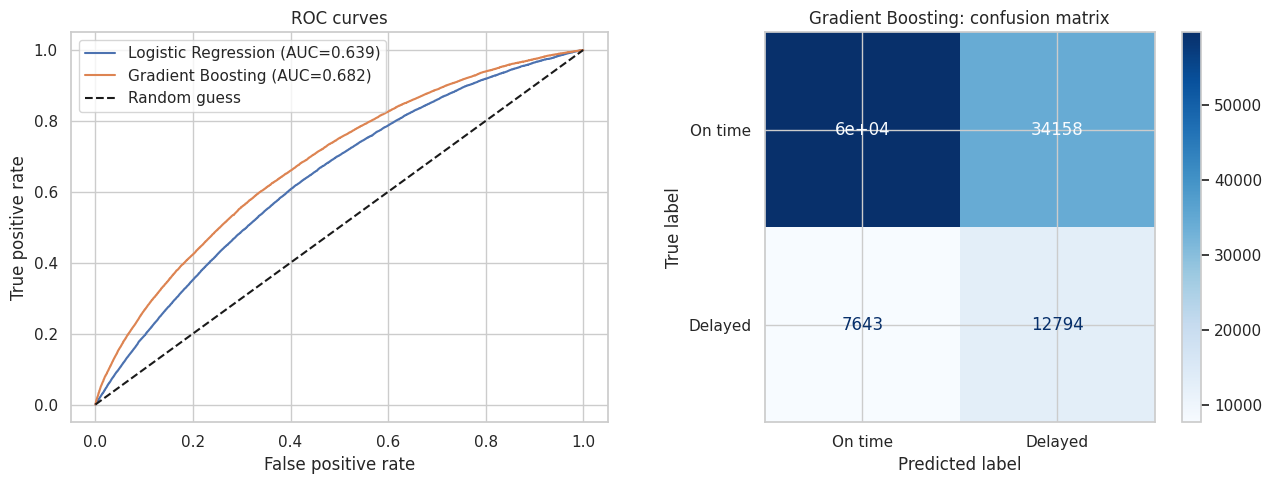

In [ ]:
from sklearn.metrics import roc_curve, ConfusionMatrixDisplay

fig, ax = plt.subplots(1, 2, figsize=(13, 5))

for name, proba in [("Logistic Regression", lr_proba), ("Gradient Boosting", gb_proba)]:
    fpr, tpr, _ = roc_curve(y_test, proba)
    ax[0].plot(fpr, tpr, label=f"{name} (AUC={roc_auc_score(y_test, proba):.3f})")
ax[0].plot([0, 1], [0, 1], "k--", label="Random guess")
ax[0].set_xlabel("False positive rate")
ax[0].set_ylabel("True positive rate")
ax[0].set_title("ROC curves")
ax[0].legend()

ConfusionMatrixDisplay.from_estimator(gb, X_test, y_test, ax=ax[1],
                                      display_labels=["On time", "Delayed"], cmap="Blues")
ax[1].set_title("Gradient Boosting: confusion matrix")
plt.tight_layout()
plt.show()

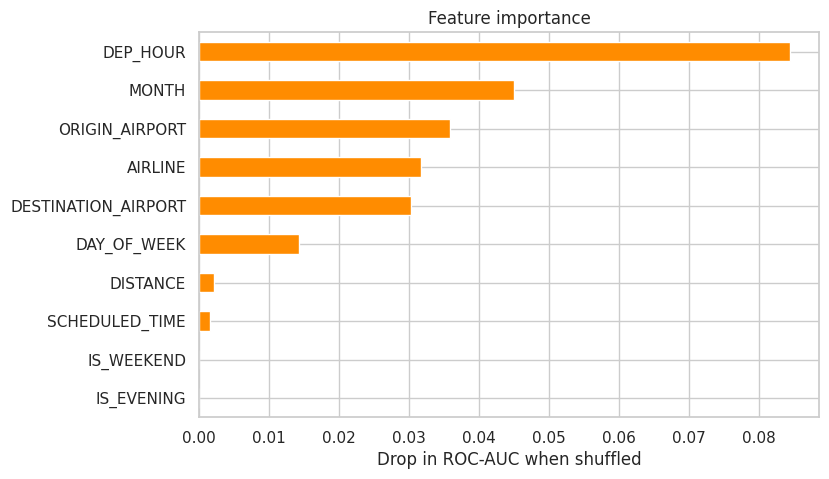

In [ ]:
from sklearn.inspection import permutation_importance

idx = X_test.sample(10_000, random_state=42).index
result = permutation_importance(gb, X_test.loc[idx], y_test.loc[idx],
                                n_repeats=5, scoring="roc_auc", random_state=42)

importances = pd.Series(result.importances_mean, index=X_test.columns).sort_values()
importances.plot(kind="barh", figsize=(8, 5), color="darkorange")
plt.xlabel("Drop in ROC-AUC when shuffled")
plt.title("Feature importance")
plt.show()

In [ ]:
ConfusionMatrixDisplay.from_estimator(gb, X_test, y_test, ax=ax[1],
    display_labels=["On time", "Delayed"], cmap="Blues", values_format="d")

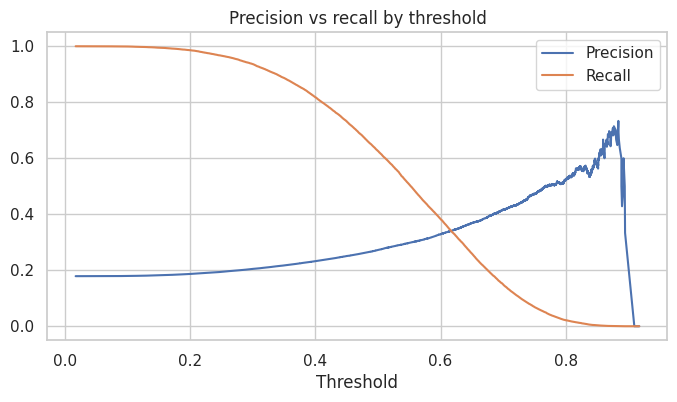

              precision    recall  f1-score   support

           0       0.86      0.83      0.84     93822
           1       0.33      0.38      0.35     20437

    accuracy                           0.75    114259
   macro avg       0.59      0.61      0.60    114259
weighted avg       0.77      0.75      0.76    114259



In [ ]:
from sklearn.metrics import precision_recall_curve

prec, rec, thr = precision_recall_curve(y_test, gb_proba)

plt.figure(figsize=(8, 4))
plt.plot(thr, prec[:-1], label="Precision")
plt.plot(thr, rec[:-1], label="Recall")
plt.xlabel("Threshold")
plt.legend()
plt.title("Precision vs recall by threshold")
plt.show()

# Example: flag only the riskiest flights
threshold = 0.6
pred = (gb_proba >= threshold).astype(int)
print(classification_report(y_test, pred))

In [ ]:
import numpy as np

f1 = 2 * prec * rec / (prec + rec + 1e-9)
best = np.argmax(f1[:-1])
print(f"Best threshold: {thr[best]:.3f} | precision {prec[best]:.2f} | recall {rec[best]:.2f} | F1 {f1[best]:.2f}")

Best threshold: 0.514 | precision 0.28 | recall 0.59 | F1 0.38


In [ ]:
cols = ["MONTH", "DAY", "DAY_OF_WEEK", "AIRLINE", "TAIL_NUMBER",
        "ORIGIN_AIRPORT", "DESTINATION_AIRPORT", "SCHEDULED_DEPARTURE",
        "SCHEDULED_TIME", "DISTANCE", "ARRIVAL_DELAY", "CANCELLED", "DIVERTED"]

full = pd.read_csv(f"{path}/flights.csv", usecols=cols, low_memory=False)
full["ORIGIN_AIRPORT"] = full["ORIGIN_AIRPORT"].astype(str)
full["DESTINATION_AIRPORT"] = full["DESTINATION_AIRPORT"].astype(str)

full = full[(full["CANCELLED"] == 0) & (full["DIVERTED"] == 0)].dropna(
    subset=["TAIL_NUMBER", "ARRIVAL_DELAY", "SCHEDULED_TIME"])

rng = np.random.default_rng(42)
tails = full["TAIL_NUMBER"].unique()
keep = rng.choice(tails, size=min(2000, len(tails)), replace=False)
d = full[full["TAIL_NUMBER"].isin(keep)].copy()
print(d.shape)

(2365436, 13)


In [ ]:
d["YEAR"] = 2015
d["DEP_HOUR"] = (d["SCHEDULED_DEPARTURE"] // 100).clip(upper=23)
d["DEP_MIN"] = d["SCHEDULED_DEPARTURE"] % 100

d["SCHED_DEP_DT"] = pd.to_datetime(
    dict(year=d["YEAR"], month=d["MONTH"], day=d["DAY"],
         hour=d["DEP_HOUR"], minute=d["DEP_MIN"].clip(upper=59)))
d["SCHED_ARR_DT"] = d["SCHED_DEP_DT"] + pd.to_timedelta(d["SCHEDULED_TIME"], unit="m")
d["ACTUAL_ARR_DT"] = d["SCHED_ARR_DT"] + pd.to_timedelta(d["ARRIVAL_DELAY"], unit="m")

In [ ]:
d = d.sort_values(["TAIL_NUMBER", "SCHED_DEP_DT"]).reset_index(drop=True)
g = d.groupby("TAIL_NUMBER")

d["PREV_ARR_DELAY"] = g["ARRIVAL_DELAY"].shift(1)
d["PREV_ACTUAL_ARR"] = g["ACTUAL_ARR_DT"].shift(1)
d["PREV_SCHED_ARR"] = g["SCHED_ARR_DT"].shift(1)
d["PREV_DEST"] = g["DESTINATION_AIRPORT"].shift(1)


valid = (
    (d["PREV_DEST"] == d["ORIGIN_AIRPORT"])
    & (d["PREV_ACTUAL_ARR"] <= d["SCHED_DEP_DT"])
    & ((d["SCHED_DEP_DT"] - d["PREV_SCHED_ARR"]) < pd.Timedelta("24h"))
)

d["PREV_ARR_DELAY"] = d["PREV_ARR_DELAY"].where(valid)
d["TURNAROUND_MIN"] = ((d["SCHED_DEP_DT"] - d["PREV_SCHED_ARR"])
                       .dt.total_seconds() / 60).where(valid)
d["HAS_PREV"] = valid.astype(int)

print(f"Flights with a valid previous leg: {valid.mean():.1%}")
d[["TAIL_NUMBER", "PREV_ARR_DELAY", "TURNAROUND_MIN"]].dropna().head()

Flights with a valid previous leg: 80.1%


,TAIL_NUMBER,PREV_ARR_DELAY,TURNAROUND_MIN
1,7819A,3.0,435.0
2,7819A,-7.0,90.0
3,7819A,-25.0,-25.0
7,7819A,88.0,430.0
8,7819A,-10.0,35.0


In [ ]:
d["IS_DELAYED"] = (d["ARRIVAL_DELAY"] > 15).astype(int)
d["IS_WEEKEND"] = d["DAY_OF_WEEK"].isin([6, 7]).astype(int)
d["IS_EVENING"] = (d["DEP_HOUR"] >= 17).astype(int)

for col in ["ORIGIN_AIRPORT", "DESTINATION_AIRPORT"]:
    top = d[col].value_counts().nlargest(100).index
    d[col] = d[col].where(d[col].isin(top), "OTHER")

base_num = ["MONTH", "DAY_OF_WEEK", "DEP_HOUR", "DISTANCE",
            "SCHEDULED_TIME", "IS_WEEKEND", "IS_EVENING"]
new_num = ["PREV_ARR_DELAY", "TURNAROUND_MIN", "HAS_PREV"]
cat = ["AIRLINE", "ORIGIN_AIRPORT", "DESTINATION_AIRPORT"]

idx_train, idx_test = train_test_split(
    d.index, test_size=0.2, random_state=42, stratify=d["IS_DELAYED"])

def run_gb(num_features, label):
    feats = num_features + cat
    prep = ColumnTransformer([
        ("num", "passthrough", num_features),
        ("cat", OrdinalEncoder(handle_unknown="use_encoded_value", unknown_value=-1), cat),
    ])
    model = Pipeline([
        ("prep", prep),
        ("clf", HistGradientBoostingClassifier(
            categorical_features=[len(num_features) + i for i in range(len(cat))],
            max_iter=200, learning_rate=0.1, class_weight="balanced", random_state=42)),
    ])
    model.fit(d.loc[idx_train, feats], d.loc[idx_train, "IS_DELAYED"])
    proba = model.predict_proba(d.loc[idx_test, feats])[:, 1]
    auc = roc_auc_score(d.loc[idx_test, "IS_DELAYED"], proba)
    print(f"{label}: ROC-AUC = {auc:.3f}")
    return model, proba

m_base, p_base = run_gb(base_num, "Without previous-flight features")
m_new, p_new = run_gb(base_num + new_num, "With previous-flight features   ")

Without previous-flight features: ROC-AUC = 0.694
With previous-flight features   : ROC-AUC = 0.799


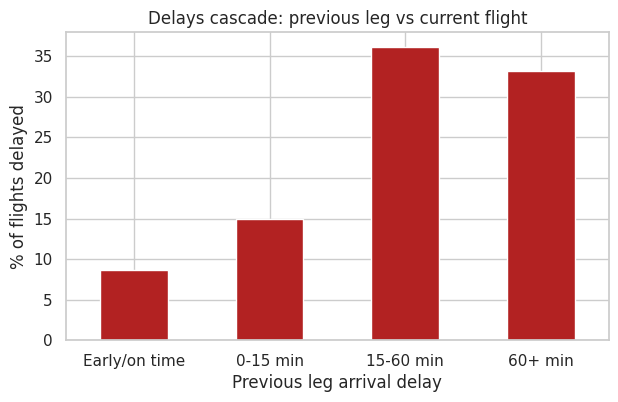

In [ ]:
d["PREV_BUCKET"] = pd.cut(d["PREV_ARR_DELAY"], [-1000, 0, 15, 60, 1000],
                          labels=["Early/on time", "0-15 min", "15-60 min", "60+ min"])
(d.groupby("PREV_BUCKET", observed=True)["IS_DELAYED"].mean() * 100).plot(
    kind="bar", color="firebrick", figsize=(7, 4))
plt.ylabel("% of flights delayed")
plt.xlabel("Previous leg arrival delay")
plt.title("Delays cascade: previous leg vs current flight")
plt.xticks(rotation=0)
plt.show()

In [ ]:
d.groupby("PREV_BUCKET", observed=True)["TURNAROUND_MIN"].median()

,TURNAROUND_MIN
PREV_BUCKET,
Early/on time,70.0
0-15 min,90.0
15-60 min,115.0
60+ min,475.0
